# Read One Patient's Details

In [1]:
import nibabel as nib  # Lets you read and work with NIfTI medical image files.
import numpy as np
import matplotlib.pyplot as plt
import os


## Get file location

In [8]:
# Base folder where dataset is stored
data_dir = r"C:\Users\lekal\Jupyter Notebooks\Model from scratch\HECKTOR 2026 Training Data (1)\HECKTOR 2026 Training Data\CHUM-006"

# The 3 files
ct_file = os.path.join(data_dir, "CHUM-006__CT.nii.gz")
pt_file = os.path.join(data_dir, "CHUM-006__PT.nii.gz")
gt_file = os.path.join(data_dir, "CHUM-006.nii.gz")

# Checking if the file exist or not
print("CT Path:", os.path.exists(ct_file))
print("PT Path:", os.path.exists(pt_file))
print("GT Path:", os.path.exists(gt_file))

CT Path: True
PT Path: True
GT Path: True


## Load the 3D scans and inspect their shapes

In [9]:
# opens and load file as numpy array 
ct_volume = nib.load(ct_file).get_fdata()
pt_volume = nib.load(pt_file).get_fdata()
gt_mask   = nib.load(gt_file).get_fdata()
print("CT volume shape:", ct_volume.shape) # row, column , slice
print("PT volume shape:", pt_volume.shape)
print("Ground Truth shape:", gt_mask.shape)
print("Labels in mask:", np.unique(gt_mask)) # 0 - background, 1,2 target region

CT volume shape: (512, 512, 240)
PT volume shape: (512, 512, 240)
Ground Truth shape: (512, 512, 240)
Labels in mask: [0. 1. 2.]


## Find which slices have tumors

In [10]:
# Count labeled tumor pixels in each slice (labels 1 or 2; label 0 is ignored)
tumor_pixels_per_slice = np.sum(gt_mask > 0, axis=(0, 1))

# Get the slice numbers where at least one tumor pixel is present
cancer_slices = np.where(tumor_pixels_per_slice > 0)[0]

# Print the total number of slices in this scan
print(f"Total slices in scan: {gt_mask.shape[2]}")

# Print the slice numbers containing tumor (numbering starts at 0)
print(f"Slices containing cancer: {cancer_slices}")

# Print how many slices contain tumor
print(f"Total cancer slices: {len(cancer_slices)}")

# Find the slice number with the most tumor pixels
best_slice = int(np.argmax(tumor_pixels_per_slice))

# Display that slice number
print(f"\n--> Slice {best_slice} has the largest tumor cross-section!")

Total slices in scan: 240
Slices containing cancer: [124 125 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141
 142 143 144 145 146 147 148 149 150 151 152 153 154 155 156]
Total cancer slices: 33

--> Slice 142 has the largest tumor cross-section!


## Display the images

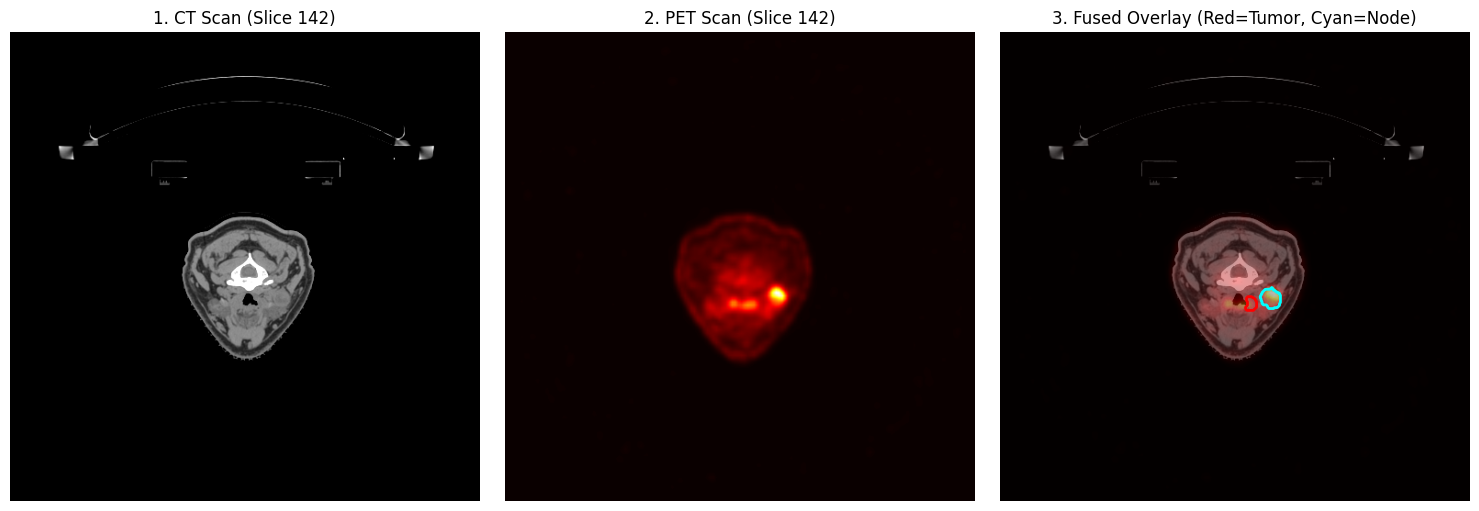

In [11]:
# Take the selected slice from the CT, PET, and mask volumes, then rotate it
ct_s = np.rot90(ct_volume[:, :, best_slice])
pt_s = np.rot90(pt_volume[:, :, best_slice])
gt_s = np.rot90(gt_mask[:, :, best_slice])

# Limit CT pixel values to this range to make the image easier to view
ct_norm = np.clip(ct_s, -160, 240)

# Create a figure with three side-by-side panels
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Show the CT slice in grayscale
axes[0].imshow(ct_norm, cmap='gray')
axes[0].set_title(f"1. CT Scan (Slice {best_slice})")  # Add a title with the slice number
axes[0].axis('off')  # Hide the axes

# Show the PET slice using a heat-style color map
axes[1].imshow(pt_s, cmap='hot')
axes[1].set_title(f"2. PET Scan (Slice {best_slice})")  # Add a title with the slice number
axes[1].axis('off')  # Hide the axes

# Show the CT slice as the background
axes[2].imshow(ct_norm, cmap='gray')

# Place the PET image on top with some transparency
axes[2].imshow(pt_s, cmap='hot', alpha=0.4)

# Draw a red outline around pixels labeled 1, if any are on this slice
if np.any(gt_s == 1):
    axes[2].contour(gt_s == 1, colors='red', linewidths=2)

# Draw a cyan outline around pixels labeled 2, if any are on this slice
if np.any(gt_s == 2):
    axes[2].contour(gt_s == 2, colors='cyan', linewidths=2)

# Add a title explaining the overlay colors
axes[2].set_title("3. Fused Overlay (Red=Tumor, Cyan=Node)")
axes[2].axis('off')  # Hide the axes

# Adjust spacing between the panels
plt.tight_layout()

# Display the three panels
plt.show()

# View 5 different patients

Viewing 5 patients: ['CHUM-001', 'CHUM-002', 'CHUM-006', 'CHUM-007', 'CHUM-008']



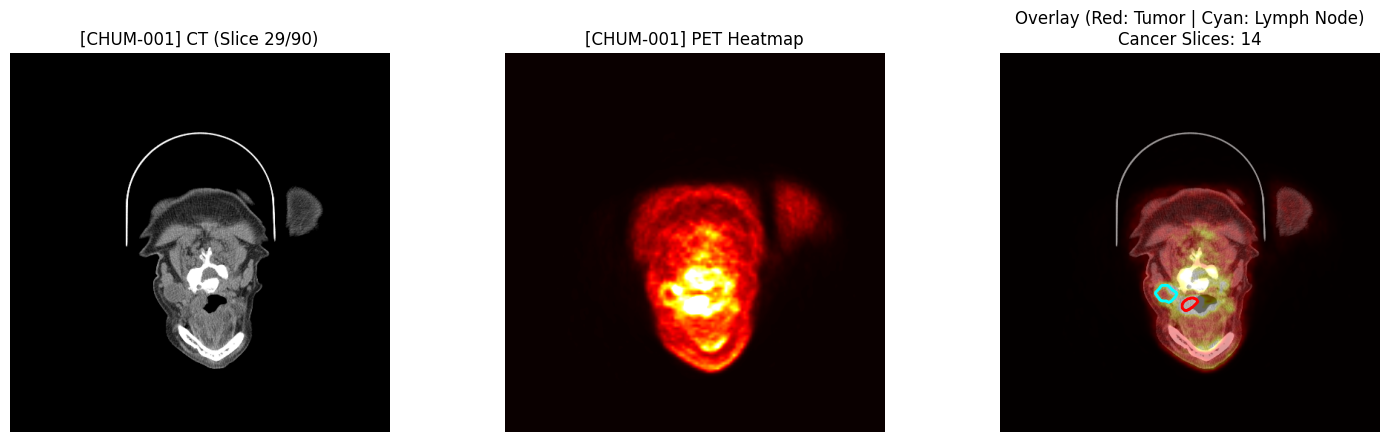

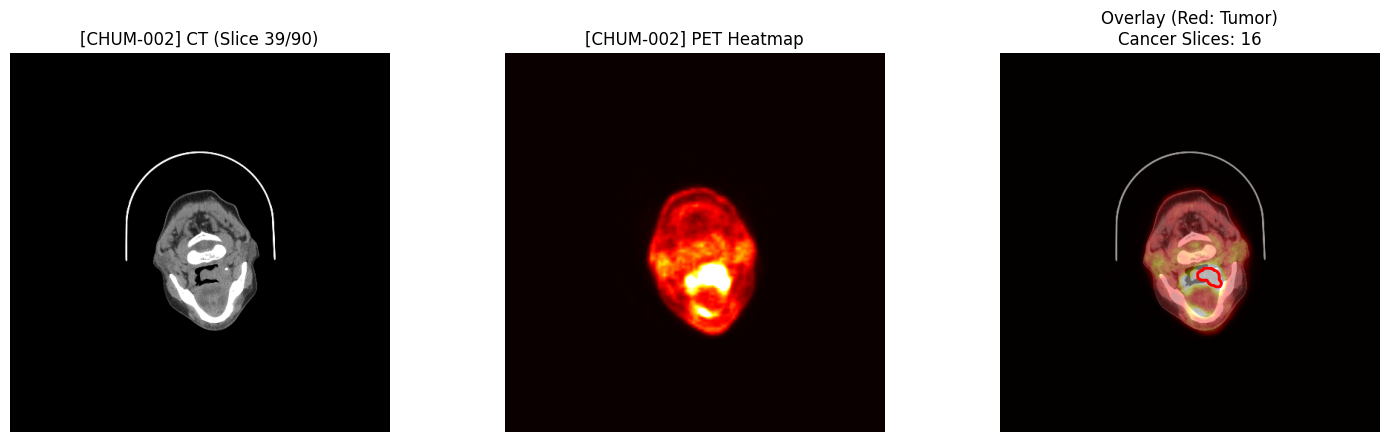

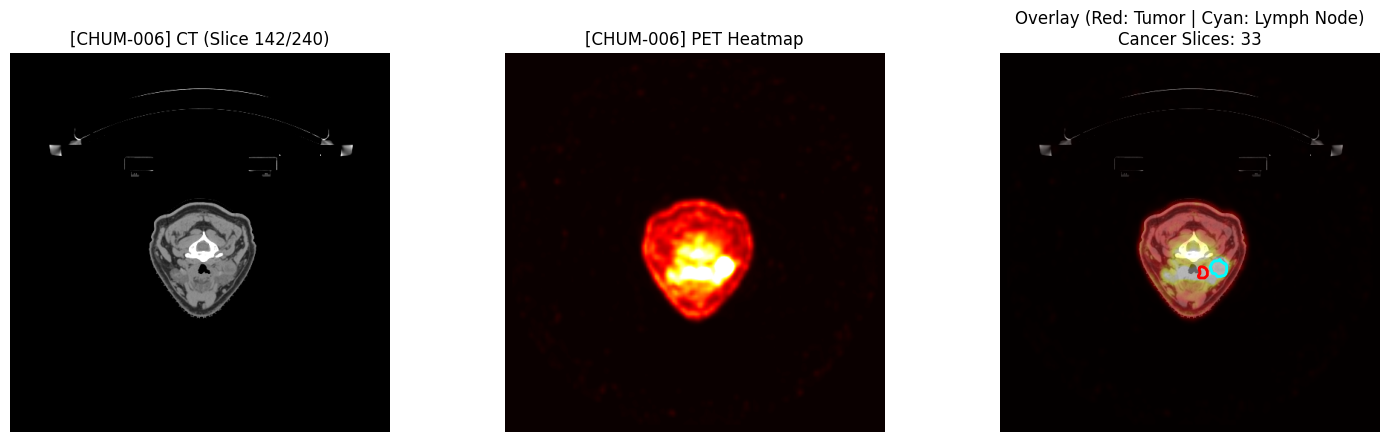

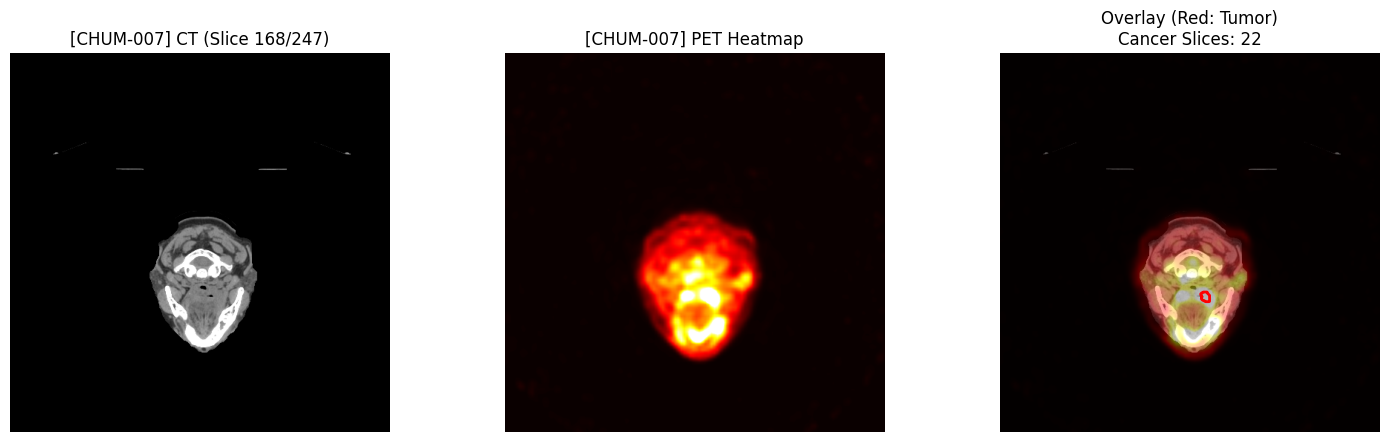

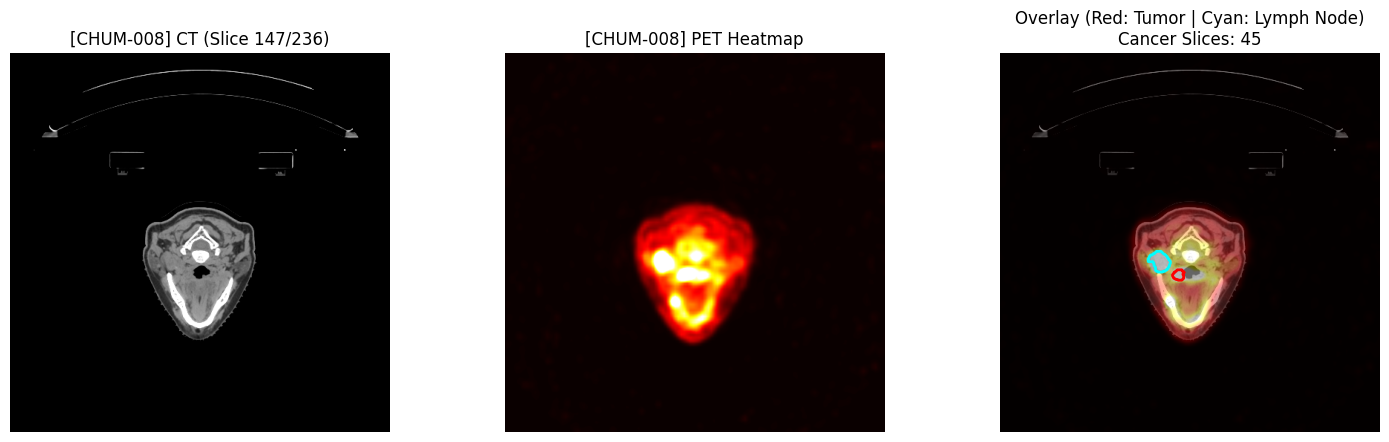

In [12]:
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

# 1. Main dataset folder containing all patient subfolders
dataset_dir = r"C:\Users\lekal\Jupyter Notebooks\Model from scratch\HECKTOR 2026 Training Data (1)\HECKTOR 2026 Training Data"

# 2. Get list of all patient folders (ignoring system folders like .ipynb_checkpoints)
all_patients = [f for f in sorted(os.listdir(dataset_dir)) if os.path.isdir(os.path.join(dataset_dir, f)) and not f.startswith('.')]

# Pick the first 5 patients
sample_patients = all_patients[:5]
print(f"Viewing 5 patients: {sample_patients}\n")

# 3. Helper function to plot 1 patient
def plot_patient_slice(patient_id):
    patient_folder = os.path.join(dataset_dir, patient_id)
    
    ct_path = os.path.join(patient_folder, f"{patient_id}__CT.nii.gz")
    pt_path = os.path.join(patient_folder, f"{patient_id}__PT.nii.gz")
    gt_path = os.path.join(patient_folder, f"{patient_id}.nii.gz")
    
    # Load volumes
    ct_vol = nib.load(ct_path).get_fdata()
    pt_vol = nib.load(pt_path).get_fdata()
    gt_vol = nib.load(gt_path).get_fdata()
    
    # Find the slice with the biggest tumor
    tumor_counts = np.sum(gt_vol > 0, axis=(0, 1))
    if np.max(tumor_counts) > 0:
        best_slice = int(np.argmax(tumor_counts))
        total_cancer_slices = int(np.sum(tumor_counts > 0))
    else:
        best_slice = gt_vol.shape[2] // 2  # middle slice if no tumor
        total_cancer_slices = 0
        
    # Extract and orient the slice
    ct_s = np.rot90(ct_vol[:, :, best_slice])
    pt_s = np.rot90(pt_vol[:, :, best_slice])
    gt_s = np.rot90(gt_vol[:, :, best_slice])
    
    # Normalize CT for soft tissue view
    ct_norm = np.clip(ct_s, -160, 240)
    
    # Normalize PET for clean heatmap view
    pt_norm = np.clip(pt_s, 0, np.percentile(pt_s, 99.5))
    if pt_norm.max() > 0:
        pt_norm = pt_norm / pt_norm.max()
        
    # Draw the 3 panels
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    
    # 1. CT
    axes[0].imshow(ct_norm, cmap='gray')
    axes[0].set_title(f"[{patient_id}] CT (Slice {best_slice}/{ct_vol.shape[2]})")
    axes[0].axis('off')
    
    # 2. PET
    axes[1].imshow(pt_norm, cmap='hot')
    axes[1].set_title(f"[{patient_id}] PET Heatmap")
    axes[1].axis('off')
    
    # 3. Fused Overlay
    axes[2].imshow(ct_norm, cmap='gray')
    axes[2].imshow(pt_norm, cmap='hot', alpha=0.4)
    
    # Draw tumor contours
    has_tumor = np.any(gt_s == 1)
    has_node = np.any(gt_s == 2)
    if has_tumor:
        axes[2].contour(gt_s == 1, colors='red', linewidths=2)
    if has_node:
        axes[2].contour(gt_s == 2, colors='cyan', linewidths=2)
        
    labels = []
    if has_tumor: labels.append("Red: Tumor")
    if has_node: labels.append("Cyan: Lymph Node")
    label_str = " | ".join(labels) if labels else "No tumor on this slice"
    
    axes[2].set_title(f"Overlay ({label_str})\nCancer Slices: {total_cancer_slices}")
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()

# 4. Loop through the 5 patients and display each one!
for pid in sample_patients:
    plot_patient_slice(pid)

## Preprocess HECKTOR Data and Extract Tumor-Containing 2D Slices

In [16]:
import os                 
import nibabel as nib         # Reads NIfTI medical image files
import numpy as np            


# Set the folder that contains the patient folders
dataset_dir = r"C:\Users\lekal\Jupyter Notebooks\Model from scratch\HECKTOR 2026 Training Data (1)\HECKTOR 2026 Training Data"

# Set the folder where the extracted 2D slices will be saved
output_dir = r"C:\Users\lekal\Jupyter Notebooks\Model from scratch\hecktor_2d_slices"

# Make separate folders for training and validation slices
train_dir = os.path.join(output_dir, "train")
val_dir = os.path.join(output_dir, "val")

# Create those folders if they do not already exist
os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)

# Get the names of the patient folders, sorted alphabetically
# Ignore hidden folders whose names start with a dot
all_patients = [
    f for f in sorted(os.listdir(dataset_dir))
    if os.path.isdir(os.path.join(dataset_dir, f)) and not f.startswith('.')
]

# Use the first 15 patients for training
train_patients = all_patients[:15]

# Use the next 5 patients for validation
val_patients = all_patients[15:20]

# Print which patients are in each group
print(f"Training on {len(train_patients)} patients: {train_patients}")
print(f"Validating on {len(val_patients)} patients: {val_patients}\n")


# Define a function that processes one patient and saves their slices
def process_patient(patient_id, save_folder):

    # Find this patient's folder
    patient_folder = os.path.join(dataset_dir, patient_id)

    # Build the file paths for the CT scan, PET scan, and ground-truth mask
    ct_path = os.path.join(patient_folder, f"{patient_id}__CT.nii.gz")
    pt_path = os.path.join(patient_folder, f"{patient_id}__PT.nii.gz")
    gt_path = os.path.join(patient_folder, f"{patient_id}.nii.gz")

    # Load each 3D file and get its image data as an array
    ct_vol = nib.load(ct_path).get_fdata()
    pt_vol = nib.load(pt_path).get_fdata()
    gt_vol = nib.load(gt_path).get_fdata()

    # Start a counter for how many slices are saved for this patient
    saved_count = 0

    # Get the number of slices from the mask's third dimension
    total_slices = gt_vol.shape[2]

    # Go through the slices one at a time
    for s in range(total_slices):

        # Get slice number s from the ground-truth mask
        gt_slice = gt_vol[:, :, s]

        # Skip this slice if it has no labeled region
        # Values greater than 0 are labels 1 or 2
        if np.sum(gt_slice > 0) == 0:
            continue

        # Get the matching CT and PET slices
        ct_slice = ct_vol[:, :, s]
        pt_slice = pt_vol[:, :, s]

        # Rotate all three slices so they display in the chosen upright direction
        ct_s = np.rot90(ct_slice)
        pt_s = np.rot90(pt_slice)
        gt_s = np.rot90(gt_slice)

        # Get the height and width of the CT slice
        h, w = ct_s.shape

        # Find the center of the slice
        cy, cx = h // 2, w // 2

        # Keep the center 256-by-256 area from each image and mask
        ct_s = ct_s[cy - 128 : cy + 128, cx - 128 : cx + 128]
        pt_s = pt_s[cy - 128 : cy + 128, cx - 128 : cx + 128]
        gt_s = gt_s[cy - 128 : cy + 128, cx - 128 : cx + 128]

        # Limit CT values to the range -160 to 240
        ct_norm = np.clip(ct_s, -160, 240)

        # Scale the CT values to range from 0 to 1
        ct_norm = (ct_norm - (-160)) / (240 - (-160))

        # Find the PET value below which 99.5% of the values fall
        pt_99 = np.percentile(pt_s, 99.5)

        # Limit unusually high PET values to that value
        # If pt_99 is not positive, keep the PET slice as it is
        pt_norm = np.clip(pt_s, 0, pt_99) if pt_99 > 0 else pt_s

        # If the PET slice has positive values, scale its largest value to 1
        if pt_norm.max() > 0:
            pt_norm = pt_norm / pt_norm.max()

        # Put the CT and PET images together as two channels
        # The resulting shape is [2, 256, 256]: CT first, PET second
        image_2ch = np.stack([ct_norm, pt_norm], axis=0).astype(np.float32)

        # Keep the mask labels as integers: 0, 1, or 2
        mask_label = gt_s.astype(np.int64)

        # Make a filename using the patient ID and slice number
        save_filename = os.path.join(save_folder, f"{patient_id}_slice{s:03d}.npz")

        # Save the two-channel image and its matching mask in a compressed file
        np.savez_compressed(save_filename, image=image_2ch, mask=mask_label)

        # Add one to the saved-slice counter
        saved_count += 1

    # Return the number of slices saved for this patient
    return saved_count


# Process and save slices for the training patients
print("--- Extracting Training Slices ---")
total_train_slices = 0

# Process each training patient
for pid in train_patients:
    n = process_patient(pid, train_dir)

    # Add this patient's saved slices to the training total
    total_train_slices += n

    # Print how many slices were saved for this patient
    print(f"Patient {pid}: Saved {n} tumor slices")


# Process and save slices for the validation patients
print("\n--- Extracting Validation Slices ---")
total_val_slices = 0

# Process each validation patient
for pid in val_patients:
    n = process_patient(pid, val_dir)

    # Add this patient's saved slices to the validation total
    total_val_slices += n

    # Print how many slices were saved for this patient
    print(f"Patient {pid}: Saved {n} tumor slices")


# Print the final totals and the folder where the files were saved
print(f"\n Finished!")
print(f"Total Training Images: {total_train_slices}")
print(f"Total Validation Images: {total_val_slices}")
print(f"Saved into: {output_dir}")

Training on 15 patients: ['CHUM-001', 'CHUM-002', 'CHUM-006', 'CHUM-007', 'CHUM-008', 'CHUM-010', 'CHUM-011', 'CHUM-012', 'CHUM-013', 'CHUM-014', 'CHUM-015', 'CHUM-016', 'CHUM-017', 'CHUM-018', 'CHUM-019']
Validating on 5 patients: ['CHUM-021', 'CHUM-022', 'CHUM-023', 'CHUM-024', 'CHUM-026']

--- Extracting Training Slices ---
Patient CHUM-001: Saved 14 tumor slices
Patient CHUM-002: Saved 16 tumor slices
Patient CHUM-006: Saved 33 tumor slices
Patient CHUM-007: Saved 22 tumor slices
Patient CHUM-008: Saved 45 tumor slices
Patient CHUM-010: Saved 38 tumor slices
Patient CHUM-011: Saved 47 tumor slices
Patient CHUM-012: Saved 36 tumor slices
Patient CHUM-013: Saved 16 tumor slices
Patient CHUM-014: Saved 50 tumor slices
Patient CHUM-015: Saved 18 tumor slices
Patient CHUM-016: Saved 69 tumor slices
Patient CHUM-017: Saved 27 tumor slices
Patient CHUM-018: Saved 15 tumor slices
Patient CHUM-019: Saved 20 tumor slices

--- Extracting Validation Slices ---
Patient CHUM-021: Saved 15 tumor 

# RUN ALL THE CODE AND THEN START TO UNDERSTAND THE CODE

## Set up the PyTorch Dataset and DataLoader

In [18]:
import os  
import glob  # Finds files that match a pattern
import torch  
from torch.utils.data import Dataset, DataLoader  
import numpy as np  

# Use the GPU if one is available; otherwise use the CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Print which device will be used
# Note: this line assumes a CUDA GPU is available
print(f"--> Using device: {device} ({torch.cuda.get_device_name(0)})")


# Define a dataset class to read the saved .npz files
class Hecktor2DDataset(Dataset):

    # Set up the dataset by finding all .npz files in the folder
    def __init__(self, folder_path):
        self.files = sorted(glob.glob(os.path.join(folder_path, "*.npz")))

    # Tell Python how many files are in this dataset
    def __len__(self):
        return len(self.files)

    # Load one file using its position number, called idx
    def __getitem__(self, idx):
        data = np.load(self.files[idx])

        # Turn the CT and PET images into a PyTorch tensor
        # Each image has 2 channels and is 256 by 256
        image = torch.tensor(data["image"], dtype=torch.float32)

        # Turn the ground-truth mask into a PyTorch tensor
        # Its values are labels 0, 1, or 2
        mask = torch.tensor(data["mask"], dtype=torch.long)

        # Return the image and its matching mask
        return image, mask


# Set the folder that contains the extracted slices
base_slice_dir = r"C:\Users\lekal\Jupyter Notebooks\Model from scratch\hecktor_2d_slices"

# Create datasets for the training and validation folders
train_dataset = Hecktor2DDataset(os.path.join(base_slice_dir, "train"))
val_dataset = Hecktor2DDataset(os.path.join(base_slice_dir, "val"))

# Load training data in groups of 8 and shuffle the order
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)

# Load validation data in groups of 8 without shuffling
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)

# Print the number of slices and groups of slices in each dataset
print(f"Loaded {len(train_dataset)} training slices ({len(train_loader)} batches)")
print(f"Loaded {len(val_dataset)} validation slices ({len(val_loader)} batches)")

--> Using device: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)
Loaded 466 training slices (59 batches)
Loaded 166 validation slices (21 batches)


## Define the 2D U-Net Model & Loss Function

In [19]:
from monai.networks.nets import UNet  
from monai.losses import DiceCELoss  

# Create a 2D U-Net model
model = UNet(
    spatial_dims=2,               # The input images are 2D slices
    in_channels=2,                # Each image has two channels: CT and PET
    out_channels=3,               # The model predicts a class for each pixel: 0, 1, or 2
    channels=(16, 32, 64, 128, 256),  # Sets the number of features used at each U-Net level
    strides=(2, 2, 2, 2),         # Shrinks the image between U-Net levels
    num_res_units=2,               # Uses two extra processing units in each level
).to(device)                       # Moves the model to the selected device (GPU or CPU)

# Create a loss function to compare predictions with the correct mask
criterion = DiceCELoss(
    to_onehot_y=True,              # Converts mask labels 0, 1, and 2 into a suitable format
    softmax=True                   # Converts model outputs into class probabilities
)

# Create the AdamW optimizer to update the model during training
optimizer = torch.optim.AdamW(
    model.parameters(),            # The model values that training will adjust
    lr=1e-3,                       # The learning rate controls the size of each update
    weight_decay=1e-4              # Adds a small penalty to help limit overly large model values
)

# Print a message that the model and optimizer have been created
print("Model created and loaded onto RTX 4050!")

C:\Users\lekal\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model created and loaded onto RTX 4050!


## Training Loop

In [21]:
import time  # Measures how long each epoch takes

num_epochs = 15  # Train the model for 15 full passes through the training data
best_val_loss = float("inf")  # Start with an extremely high validation loss
save_path = r"C:\Users\lekal\Jupyter Notebooks\Model from scratch\best_hecktor_2d_unet.pth"  # Where to save the best model

print(f" Starting training for {num_epochs} epochs...\n")

# Repeat the training and validation process for each epoch
for epoch in range(1, num_epochs + 1):
    start_time = time.time()  # Record when this epoch starts
    
    # --- TRAINING PHASE ---
    model.train()  # Put the model in training mode
    train_loss = 0.0  # Start counting this epoch's training loss

    # Go through the training data one batch at a time
    for images, masks in train_loader:
        images = images.to(device)  # Move the images to the GPU or CPU

        # Add a channel dimension to each mask
        # Shape changes from [batch, height, width] to [batch, 1, height, width]
        masks = masks.unsqueeze(1).to(device)
        
        optimizer.zero_grad()  # Clear gradients left over from the previous batch
        outputs = model(images)  # Get the model's predictions
        loss = criterion(outputs, masks)  # Compare predictions with the correct masks
        loss.backward()  # Calculate how to adjust the model's weights
        optimizer.step()  # Update the model's weights
        
        train_loss += loss.item()  # Add this batch's loss to the total
        
    # Calculate the average training loss across all batches
    avg_train_loss = train_loss / len(train_loader)
    
    # --- VALIDATION PHASE ---
    model.eval()  # Put the model in evaluation mode
    val_loss = 0.0  # Start counting this epoch's validation loss

    # Turn off gradient calculations because the model isn't being trained here
    with torch.no_grad():
        # Go through the validation data one batch at a time
        for images, masks in val_loader:
            images = images.to(device)  # Move the images to the GPU or CPU
            masks = masks.unsqueeze(1).to(device)  # Add a channel dimension to the masks
            outputs = model(images)  # Get predictions for the validation images
            loss = criterion(outputs, masks)  # Compare predictions with the correct masks
            val_loss += loss.item()  # Add this batch's loss to the total
            
    # Calculate the average validation loss across all batches
    avg_val_loss = val_loss / len(val_loader)

    # Calculate how many seconds this epoch took
    elapsed = time.time() - start_time
    
    # Save the model if its validation loss is lower than the previous best
    saved_flag = ""
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss  # Remember the new best validation loss
        torch.save(model.state_dict(), save_path)  # Save the model's learned weights
        saved_flag = " (Best Model Saved!)"
        
    # Print the training loss, validation loss, and time for this epoch
    print(
        f"Epoch [{epoch:02d}/{num_epochs:02d}] - "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Time: {elapsed:.1f}s {saved_flag}"
    )

# Print where the best model's weights were saved
print(f"\n Training Complete! Best model saved to:\n{save_path}")

 Starting training for 15 epochs...

Epoch [01/15] - Train Loss: 0.3470 | Val Loss: 0.4654 | Time: 6.9s  (Best Model Saved!)
Epoch [02/15] - Train Loss: 0.3328 | Val Loss: 0.4746 | Time: 6.5s 
Epoch [03/15] - Train Loss: 0.3271 | Val Loss: 0.4940 | Time: 6.3s 
Epoch [04/15] - Train Loss: 0.3256 | Val Loss: 0.4852 | Time: 6.5s 
Epoch [05/15] - Train Loss: 0.3218 | Val Loss: 0.4618 | Time: 6.6s  (Best Model Saved!)
Epoch [06/15] - Train Loss: 0.3138 | Val Loss: 0.4554 | Time: 6.5s  (Best Model Saved!)
Epoch [07/15] - Train Loss: 0.3078 | Val Loss: 0.4710 | Time: 6.4s 
Epoch [08/15] - Train Loss: 0.3008 | Val Loss: 0.4723 | Time: 6.1s 
Epoch [09/15] - Train Loss: 0.2987 | Val Loss: 0.4731 | Time: 6.3s 
Epoch [10/15] - Train Loss: 0.2961 | Val Loss: 0.4724 | Time: 6.3s 
Epoch [11/15] - Train Loss: 0.2924 | Val Loss: 0.4808 | Time: 6.3s 
Epoch [12/15] - Train Loss: 0.2913 | Val Loss: 0.4628 | Time: 6.3s 
Epoch [13/15] - Train Loss: 0.2872 | Val Loss: 0.4634 | Time: 6.4s 
Epoch [14/15] - Tra

C:\Users\lekal\AppData\Local\Temp\ipykernel_31892\1477834763.py:19: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  eval_model.load_state_dict(torch.load(model_path, map_locat

Trained model successfully loaded!


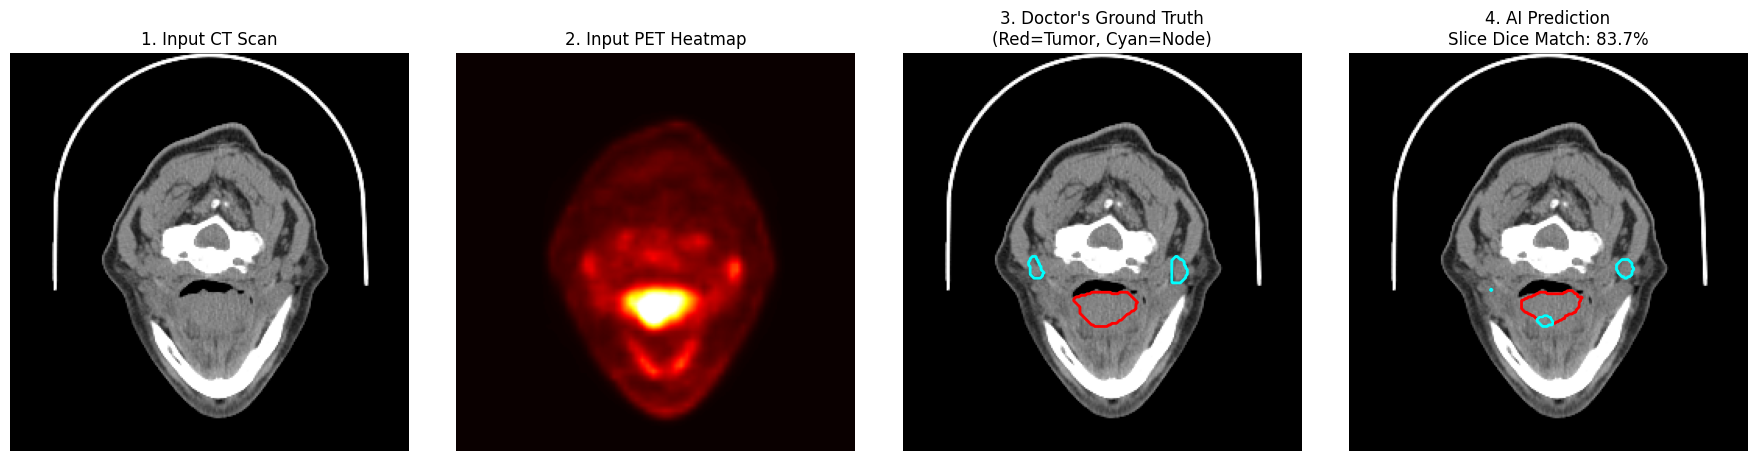

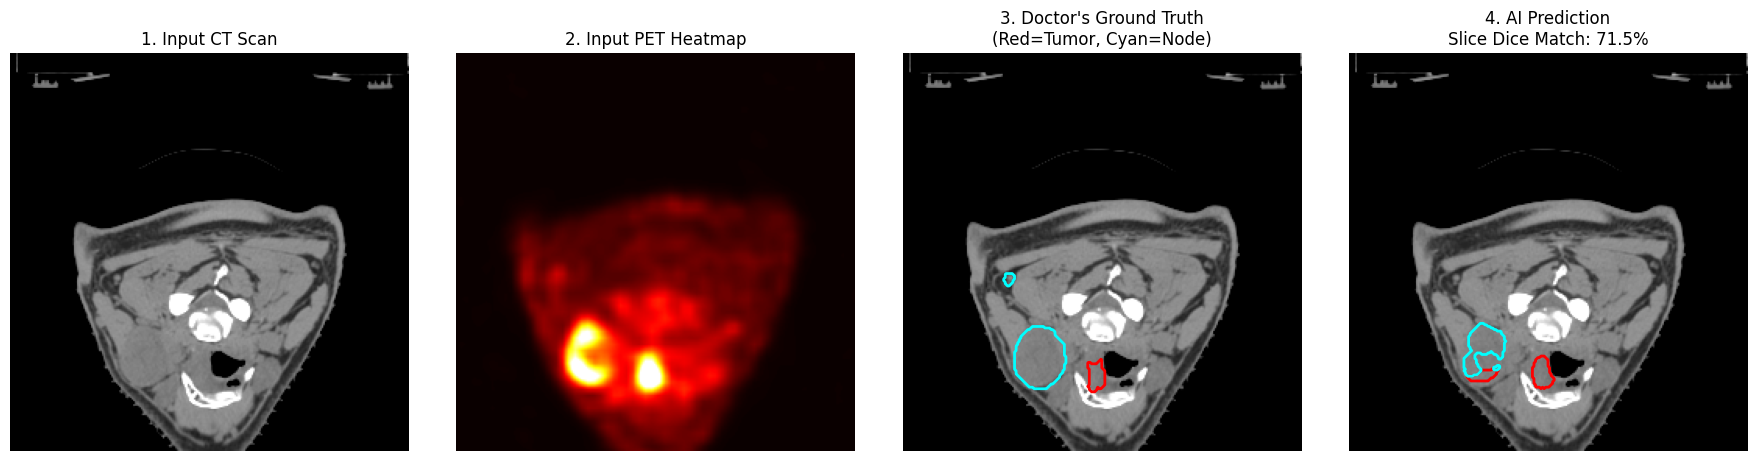

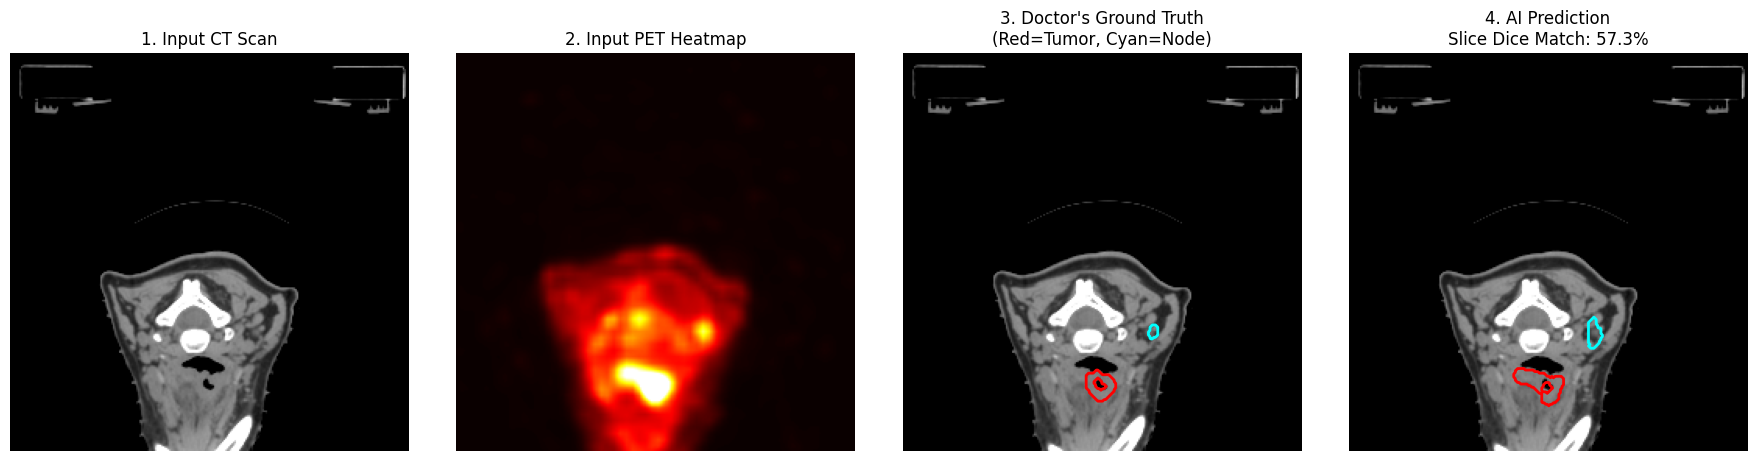

In [22]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from monai.networks.nets import UNet

# 1. Load the model and restore the trained weights
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

eval_model = UNet(
    spatial_dims=2,
    in_channels=2,
    out_channels=3,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
).to(device)

model_path = r"C:\Users\lekal\Jupyter Notebooks\Model from scratch\best_hecktor_2d_unet.pth"
eval_model.load_state_dict(torch.load(model_path, map_location=device))
eval_model.eval()

print("Trained model successfully loaded!")

# 2. Pick 3 different test slices from the validation set to inspect
sample_indices = [10, 40, 80] # You can change these numbers to see different slices!

for idx in sample_indices:
    image_tensor, mask_tensor = val_dataset[idx]
    
    # Run the AI prediction
    with torch.no_grad():
        input_batch = image_tensor.unsqueeze(0).to(device) # add batch dim: [1, 2, 256, 256]
        output = eval_model(input_batch)
        # argmax picks the highest probability class for each pixel (0, 1, or 2)
        prediction = torch.argmax(output, dim=1).squeeze(0).cpu().numpy()
        
    ct_img = image_tensor[0].cpu().numpy()
    pt_img = image_tensor[1].cpu().numpy()
    gt_img = mask_tensor.cpu().numpy()
    
    # Compute Dice score for this specific slice
    # Dice = 2 * (pred & gt) / (pred + gt)
    pred_tumor = (prediction > 0)
    gt_tumor = (gt_img > 0)
    intersection = np.logical_and(pred_tumor, gt_tumor).sum()
    dice_score = (2.0 * intersection) / (pred_tumor.sum() + gt_tumor.sum() + 1e-8)
    
    # Draw the 4-panel comparison
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
    
    # Panel 1: CT
    axes[0].imshow(ct_img, cmap='gray')
    axes[0].set_title("1. Input CT Scan")
    axes[0].axis('off')
    
    # Panel 2: PET
    axes[1].imshow(pt_img, cmap='hot')
    axes[1].set_title("2. Input PET Heatmap")
    axes[1].axis('off')
    
    # Panel 3: Ground Truth (Doctor)
    axes[2].imshow(ct_img, cmap='gray')
    if np.any(gt_img == 1):
        axes[2].contour(gt_img == 1, colors='red', linewidths=2)
    if np.any(gt_img == 2):
        axes[2].contour(gt_img == 2, colors='cyan', linewidths=2)
    axes[2].set_title("3. Doctor's Ground Truth\n(Red=Tumor, Cyan=Node)")
    axes[2].axis('off')
    
    # Panel 4: AI Prediction
    axes[3].imshow(ct_img, cmap='gray')
    if np.any(prediction == 1):
        axes[3].contour(prediction == 1, colors='red', linewidths=2)
    if np.any(prediction == 2):
        axes[3].contour(prediction == 2, colors='cyan', linewidths=2)
    axes[3].set_title(f"4. AI Prediction\nSlice Dice Match: {dice_score * 100:.1f}%")
    axes[3].axis('off')
    
    plt.tight_layout()
    plt.show()

In [23]:
# Calculate the overall average Dice score across ALL 166 validation slices
eval_model.eval()
total_dice = []

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(device)
        outputs = eval_model(images)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        gts = masks.numpy()
        
        for p, g in zip(preds, gts):
            p_cancer = (p > 0)
            g_cancer = (g > 0)
            if g_cancer.sum() > 0: # only evaluate slices that have cancer
                intersection = np.logical_and(p_cancer, g_cancer).sum()
                d = (2.0 * intersection) / (p_cancer.sum() + g_cancer.sum() + 1e-8)
                total_dice.append(d)

mean_score = np.mean(total_dice) * 100
print(f"==================================================")
print(f"📊 OVERALL VALIDATION SCORE: {mean_score:.2f}% Dice")
print(f"==================================================")

📊 OVERALL VALIDATION SCORE: 58.45% Dice
